In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!pip -q install lime shap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 15.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [4]:
# =============================================================================
# SECTION 1 : IMPORT LIBRARIES
# =============================================================================

import os
import warnings
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import shap
import lime
import lime.lime_tabular

from IPython.display import display

warnings.filterwarnings("ignore")

print("=" * 80)
print("SECTION 1 COMPLETED")
print("Libraries Imported Successfully")
print("=" * 80)

SECTION 1 COMPLETED
Libraries Imported Successfully


In [10]:
# =============================================================================
# SECTION 2 : PROJECT DIRECTORY SETUP
# =============================================================================



PROJECT_DIR = "/content/drive/MyDrive/CKD Research Project"

DATASET_DIR = os.path.join(PROJECT_DIR, "Dataset")
RESULT_DIR = os.path.join(PROJECT_DIR, "Results")
MODEL_DIR = os.path.join(PROJECT_DIR, "Saved_Models")
FIGURE_DIR = os.path.join(PROJECT_DIR, "Figures")

# ---------------------------------------------------------------------
# Create publication folders
# ---------------------------------------------------------------------


ML_FIGURE_DIR = os.path.join(FIGURE_DIR, "Machine_Learning")
XAI_FIGURE_DIR = os.path.join(FIGURE_DIR, "Explainable_AI")



os.makedirs(ML_FIGURE_DIR, exist_ok=True)
os.makedirs(XAI_FIGURE_DIR, exist_ok=True)

print("="*80)
print("PROJECT DIRECTORY READY")
print("="*80)

print(PROJECT_DIR)

PROJECT DIRECTORY READY
/content/drive/MyDrive/CKD Research Project


In [11]:
# =============================================================================
# SECTION 3 : LOAD DATASET
# =============================================================================

dataset_path = os.path.join(
    DATASET_DIR,
    "clean_ckd.csv"
)

df = pd.read_csv(dataset_path)

print("="*80)
print("DATASET LOADED")
print("="*80)

print(df.shape)

display(df.head())

DATASET LOADED
(399, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.20000,1,1,0,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,121.0,...,38.0,6000.0,4.70709,0,0,0,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.70709,0,1,0,1,0,1,0
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.90000,1,0,0,1,1,1,0
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.60000,0,0,0,0,0,0,0


In [12]:
# =============================================================================
# SECTION 4 : PREPARE FEATURES
# =============================================================================

TARGET_COLUMN = "class"

X = df.drop(columns=[TARGET_COLUMN])

y = df[TARGET_COLUMN]

feature_names = X.columns.tolist()

print("="*80)
print("FEATURE MATRIX READY")
print("="*80)

print("X Shape :", X.shape)
print("y Shape :", y.shape)

FEATURE MATRIX READY
X Shape : (399, 24)
y Shape : (399,)


In [13]:
# =============================================================================
# SECTION 5 : LOAD MODEL COMPARISON RESULTS
# =============================================================================

comparison_file = os.path.join(
    RESULT_DIR,
    "model_comparison.csv"
)

comparison_df = pd.read_csv(comparison_file)



comparison_df = comparison_df[
    ~comparison_df["Model"].str.contains(
        "SVC|Support Vector Machine",
        case=False,
        na=False
    )
].reset_index(drop=True)

print("=" * 80)
print("MODEL COMPARISON RESULTS")
print("=" * 80)

display(comparison_df)

print("\nAvailable Models:")
print(comparison_df["Model"].tolist())

MODEL COMPARISON RESULTS


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,LogisticRegression,0.9875,0.967742,1.000000,0.983607,0.999333
1,KNeighborsClassifier,0.9875,0.967742,1.000000,0.983607,0.989000
2,ExtraTreesClassifier,0.9875,1.000000,0.966667,0.983051,1.000000
3,RandomForestClassifier,0.9750,1.000000,0.933333,0.965517,0.999333
4,DecisionTreeClassifier,0.9750,1.000000,0.933333,0.965517,0.966667
5,GaussianNB,0.9750,0.937500,1.000000,0.967742,1.000000
6,CatBoostClassifier,0.9750,1.000000,0.933333,0.965517,0.999333
7,LGBMClassifier,0.9750,1.000000,0.933333,0.965517,1.000000
8,XGBClassifier,0.9625,1.000000,0.900000,0.947368,0.999333



Available Models:
['LogisticRegression', 'KNeighborsClassifier', 'ExtraTreesClassifier', 'RandomForestClassifier', 'DecisionTreeClassifier', 'GaussianNB', 'CatBoostClassifier', 'LGBMClassifier', 'XGBClassifier']


In [14]:
# =============================================================================
# SECTION 6 : AUTOMATIC BEST MODEL SELECTION
# =============================================================================

print("=" * 80)
print("AUTOMATIC BEST MODEL SELECTION")
print("=" * 80)

# -----------------------------------------------------------
# Sort models by performance
# -----------------------------------------------------------

ranking_df = comparison_df.sort_values(
    by=["ROC_AUC", "F1", "Accuracy", "Precision", "Recall"],
    ascending=False
).reset_index(drop=True)

# -----------------------------------------------------------
# Display Ranking
# -----------------------------------------------------------

print("\nModel Ranking:\n")

display(ranking_df)

# -----------------------------------------------------------
# Candidate Models
# -----------------------------------------------------------

top_model = ranking_df.iloc[0]
second_model = ranking_df.iloc[1]

# -----------------------------------------------------------
# Tolerance
# -----------------------------------------------------------

TOL = 0.001

# -----------------------------------------------------------
# Check whether Logistic Regression and Extra Trees
# are essentially identical
# -----------------------------------------------------------

candidate_models = {
    top_model["Model"],
    second_model["Model"]
}

extra_tree_names = [
    "Extra Trees",
    "ExtraTrees",
    "ExtraTreesClassifier"
]

logistic_names = [
    "Logistic Regression",
    "LogisticRegression"
]

if (
    any(x in candidate_models for x in extra_tree_names)
    and
    any(x in candidate_models for x in logistic_names)
):

    extra_row = ranking_df[
        ranking_df["Model"].isin(extra_tree_names)
    ].iloc[0]

    lr_row = ranking_df[
        ranking_df["Model"].isin(logistic_names)
    ].iloc[0]

    metrics = [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC"
    ]

    almost_equal = all(

        abs(extra_row[m] - lr_row[m]) <= TOL

        for m in metrics

    )

    if almost_equal:

        best_model_name = extra_row["Model"]

        print("\nSimilar performance detected.")
        print("Extra Trees selected for Explainable AI.")

    else:

        best_model_name = top_model["Model"]

else:

    best_model_name = top_model["Model"]

# -----------------------------------------------------------
# Final Model
# -----------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL BEST MODEL")
print("=" * 80)

print(best_model_name)

AUTOMATIC BEST MODEL SELECTION

Model Ranking:



,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,ExtraTreesClassifier,0.9875,1.000000,0.966667,0.983051,1.000000
1,GaussianNB,0.9750,0.937500,1.000000,0.967742,1.000000
2,LGBMClassifier,0.9750,1.000000,0.933333,0.965517,1.000000
3,RandomForestClassifier,0.9750,1.000000,0.933333,0.965517,0.999333
4,LogisticRegression,0.9875,0.967742,1.000000,0.983607,0.999333
5,CatBoostClassifier,0.9750,1.000000,0.933333,0.965517,0.999333
6,XGBClassifier,0.9625,1.000000,0.900000,0.947368,0.999333
7,KNeighborsClassifier,0.9875,0.967742,1.000000,0.983607,0.989000
8,DecisionTreeClassifier,0.9750,1.000000,0.933333,0.965517,0.966667



FINAL BEST MODEL
ExtraTreesClassifier


In [15]:
# =============================================================================
# SECTION 7 : LOAD THE SELECTED BEST MODEL
# =============================================================================

print("=" * 80)
print("LOADING SELECTED BEST MODEL")
print("=" * 80)

# ------------------------------------------------------------------
# Current available saved models
# ------------------------------------------------------------------

MODEL_FILE_MAP = {

    "Extra Trees": "extra_trees.pkl",
    "ExtraTrees": "extra_trees.pkl",
    "ExtraTreesClassifier": "extra_trees.pkl",

    "Random Forest": "RandomForest.pkl",
    "RandomForest": "RandomForest.pkl",
    "RandomForestClassifier": "RandomForest.pkl"
}

# ------------------------------------------------------------------
# Check whether selected model exists
# ------------------------------------------------------------------

if best_model_name not in MODEL_FILE_MAP:
    raise ValueError(
        f"\nSaved model for '{best_model_name}' is not available.\n"
        "Currently available models are:\n"
        f"{list(MODEL_FILE_MAP.keys())}"
    )

model_path = os.path.join(
    MODEL_DIR,
    MODEL_FILE_MAP[best_model_name]
)

# ------------------------------------------------------------------
# Load Model
# ------------------------------------------------------------------

best_model = joblib.load(model_path)

print("\nBest Model Successfully Loaded")
print("-" * 80)

print(f"Selected Model : {best_model_name}")
print(f"Model File     : {MODEL_FILE_MAP[best_model_name]}")
print(f"Model Path     : {model_path}")

print("=" * 80)

LOADING SELECTED BEST MODEL

Best Model Successfully Loaded
--------------------------------------------------------------------------------
Selected Model : ExtraTreesClassifier
Model File     : extra_trees.pkl
Model Path     : /content/drive/MyDrive/CKD Research Project/Saved_Models/extra_trees.pkl


In [19]:
# =============================================================================
# SECTION 8 : BEST MODEL SUMMARY
# =============================================================================

print("=" * 80)
print("BEST MODEL SUMMARY")
print("=" * 80)

best_model_summary = ranking_df[
    ranking_df["Model"] == best_model_name
]

display(best_model_summary)





print("\nBest Model Summary Saved Successfully")


BEST MODEL SUMMARY


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,ExtraTreesClassifier,0.9875,1.0,0.966667,0.983051,1.0



Best Model Summary Saved Successfully


In [20]:
# =============================================================================
# SECTION 9 :SHAP EXPLAINER INITIALIZATION
# =============================================================================

print("=" * 80)
print("INITIALIZING SHAP EXPLAINER")
print("=" * 80)

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------------
# Detect Model Type
# ------------------------------------------------------------------

if isinstance(
    best_model,
    (
        RandomForestClassifier,
        ExtraTreesClassifier,
        DecisionTreeClassifier
    )
):

    model_type = "Tree"

elif isinstance(
    best_model,
    LogisticRegression
):

    model_type = "Linear"

else:

    model_type = "Kernel"

print(f"Detected Model Type : {model_type}")

# ------------------------------------------------------------------
# Create SHAP Explainer
# ------------------------------------------------------------------

if model_type == "Tree":

    explainer = shap.TreeExplainer(best_model)

elif model_type == "Linear":

    explainer = shap.LinearExplainer(best_model, X)

else:

    background = shap.sample(X, 100, random_state=42)

    explainer = shap.KernelExplainer(
        best_model.predict_proba,
        background
    )

print("SHAP Explainer Initialized Successfully")

INITIALIZING SHAP EXPLAINER
Detected Model Type : Tree
SHAP Explainer Initialized Successfully


In [21]:
# =============================================================================
# SECTION 10 : COMPUTE SHAP VALUES
# =============================================================================

print("=" * 80)
print("COMPUTING SHAP VALUES")
print("=" * 80)

# ------------------------------------------------------------------
# Compute SHAP Values
# ------------------------------------------------------------------

shap_values = explainer(X)

# ------------------------------------------------------------------
# Binary Classification Adjustment
# ------------------------------------------------------------------

if isinstance(shap_values, list):

    shap_values = shap_values[1]

print("SHAP Values Computed Successfully")

print(f"Number of Samples : {X.shape[0]}")
print(f"Number of Features: {X.shape[1]}")

COMPUTING SHAP VALUES
SHAP Values Computed Successfully
Number of Samples : 399
Number of Features: 24


GENERATING SHAP SUMMARY PLOT


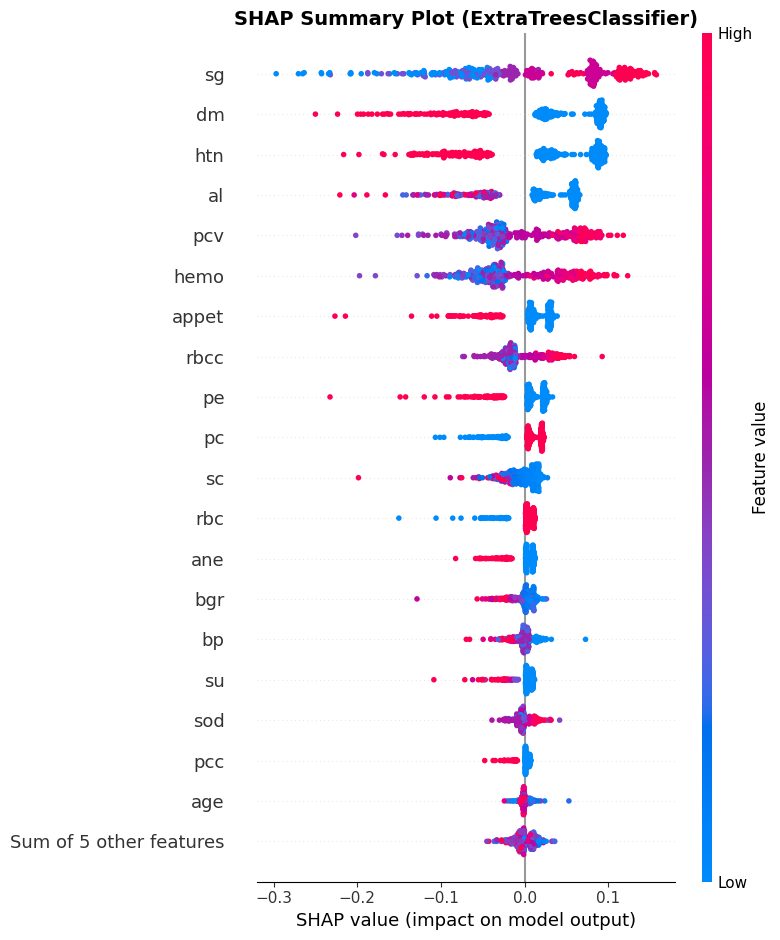


SHAP Summary Plot Saved Successfully
/content/drive/MyDrive/CKD Research Project/Figures/Explainable_AI/SHAP_Summary_Plot.png

SECTION COMPLETED


In [36]:
# =============================================================================
# SECTION 11 : SHAP SUMMARY PLOT
# =============================================================================

print("=" * 80)
print("GENERATING SHAP SUMMARY PLOT")
print("=" * 80)

# ------------------------------------------------------------------
# Prepare SHAP Explanation (Compatible with SHAP >= 0.45)
# ------------------------------------------------------------------

if len(shap_values.values.shape) == 3:

    # Binary Classification -> Positive Class (CKD)
    shap_plot = shap.Explanation(
        values=shap_values.values[:, :, 1],
        base_values=shap_values.base_values[:, 1],
        data=shap_values.data,
        feature_names=shap_values.feature_names
    )

else:

    shap_plot = shap_values

# ------------------------------------------------------------------
# SHAP Beeswarm Summary Plot
# ------------------------------------------------------------------

plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_plot,
    max_display=20,
    show=False
)

plt.title(
    f"SHAP Summary Plot ({best_model_name})",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# ------------------------------------------------------------------
# Save Figure
# ------------------------------------------------------------------

summary_png = os.path.join(
    XAI_FIGURE_DIR,
    "SHAP_Summary_Plot.png"
)

plt.savefig(
    summary_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nSHAP Summary Plot Saved Successfully")
print(summary_png)

print("\n" + "=" * 80)
print("SECTION COMPLETED")
print("=" * 80)

In [37]:
# ==========================================================
# SHAP Feature Importance Table
# ==========================================================

import numpy as np

# Binary classification compatibility
if len(shap_values.values.shape) == 3:
    shap_data = shap_values.values[:, :, 1]   # Positive class (CKD)
else:
    shap_data = shap_values.values

# Mean Absolute SHAP Value
shap_importance = pd.DataFrame({
    "Feature": X.columns,
    "Mean_SHAP": np.abs(shap_data).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_SHAP",
    ascending=False
).reset_index(drop=True)

# Top 15 Features
print("="*60)
print("TOP SHAP FEATURES")
print("="*60)

display(shap_importance.head(15))

TOP SHAP FEATURES


,Feature,Mean_SHAP
0,sg,0.080732
1,dm,0.072942
2,htn,0.070147
3,al,0.051970
4,pcv,0.049214
5,hemo,0.048914
6,appet,0.026042
7,rbcc,0.023324
8,pe,0.021133
9,pc,0.017297


GENERATING SHAP FEATURE IMPORTANCE


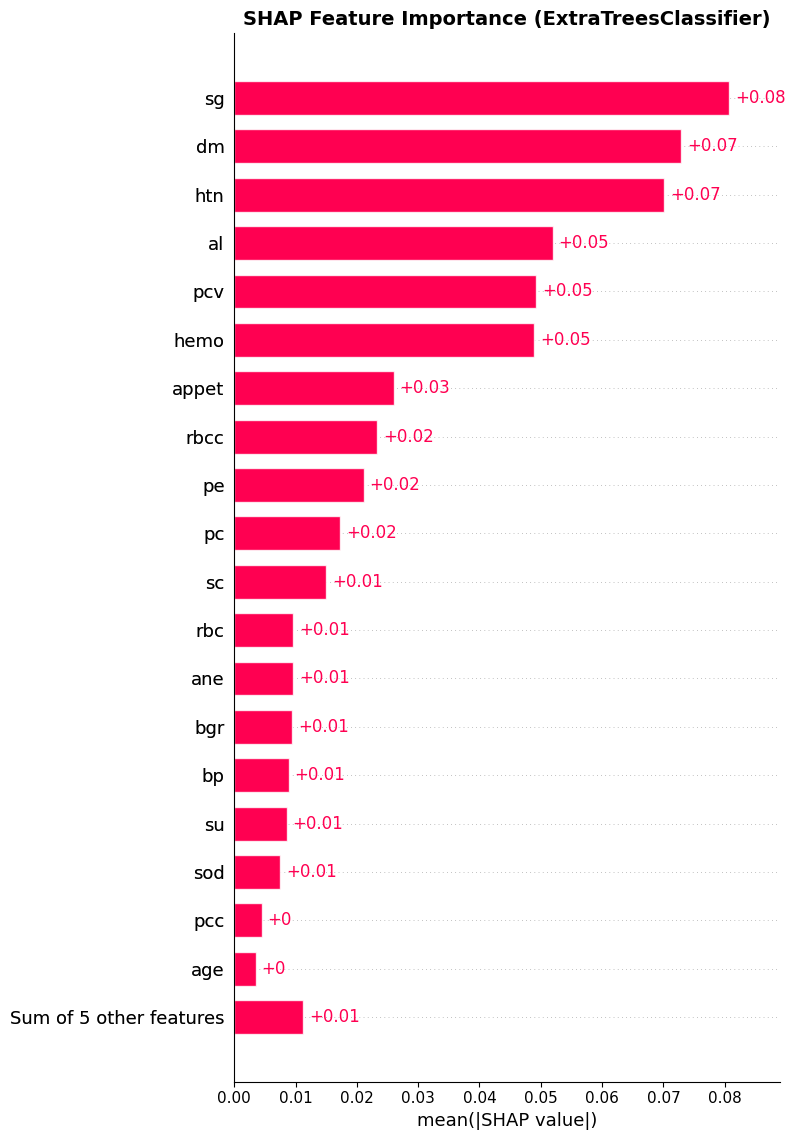


SHAP Feature Importance Plot Saved Successfully
/content/drive/MyDrive/CKD Research Project/Figures/Explainable_AI/SHAP_Feature_Importance.png
/content/drive/MyDrive/CKD Research Project/Figures/Explainable_AI/SHAP_Feature_Importance.pdf


In [23]:
# =============================================================================
# SECTION 12 : SHAP FEATURE IMPORTANCE BAR PLOT
# =============================================================================

print("=" * 80)
print("GENERATING SHAP FEATURE IMPORTANCE")
print("=" * 80)

plt.figure(figsize=(10,7))

shap.plots.bar(
    shap_plot,
    max_display=20,
    show=False
)

plt.title(
    f"SHAP Feature Importance ({best_model_name})",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

bar_png = os.path.join(
    XAI_FIGURE_DIR,
    "SHAP_Feature_Importance.png"
)

bar_pdf = os.path.join(
    XAI_FIGURE_DIR,
    "SHAP_Feature_Importance.pdf"
)

plt.savefig(
    bar_png,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    bar_pdf,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSHAP Feature Importance Plot Saved Successfully")
print(bar_png)
print(bar_pdf)

GENERATING SHAP WATERFALL PLOT


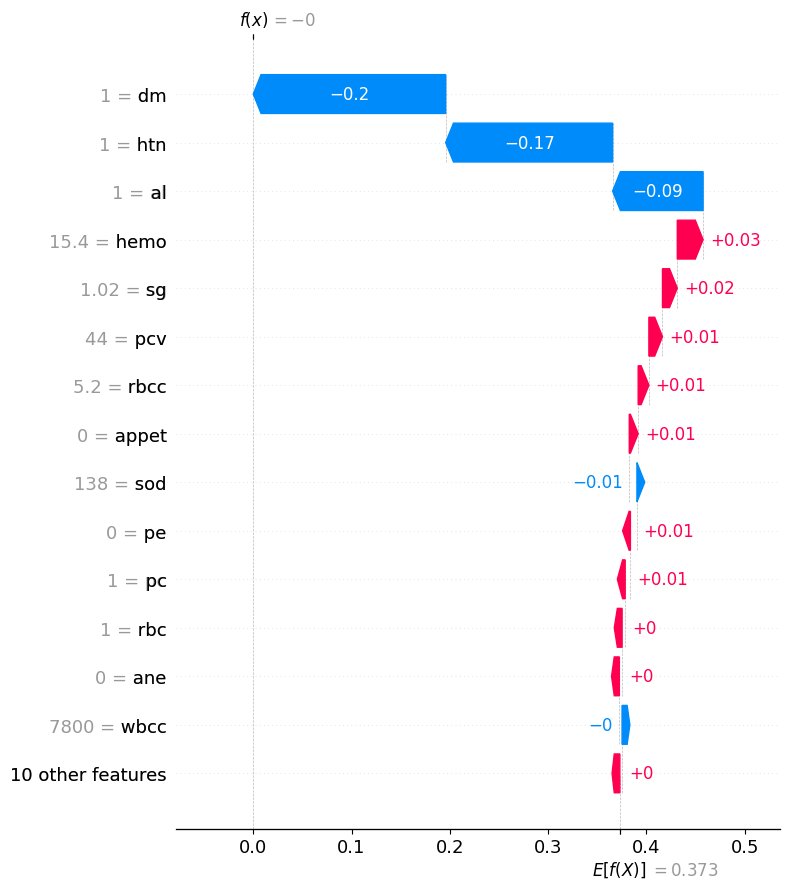


SHAP Waterfall Plot Saved Successfully
/content/drive/MyDrive/CKD Research Project/Figures/Explainable_AI/SHAP_Waterfall_Plot.png
/content/drive/MyDrive/CKD Research Project/Figures/Explainable_AI/SHAP_Waterfall_Plot.pdf


In [38]:
# =============================================================================
# SECTION 13 : SHAP WATERFALL PLOT
# =============================================================================

print("=" * 80)
print("GENERATING SHAP WATERFALL PLOT")
print("=" * 80)

# ------------------------------------------------------------------
# Select Sample
# ------------------------------------------------------------------

sample_index = 0

# ------------------------------------------------------------------
# Generate Waterfall Plot
# ------------------------------------------------------------------

plt.figure(figsize=(10, 8))

shap.plots.waterfall(
    shap_plot[sample_index],
    max_display=15,
    show=False
)

plt.tight_layout()

waterfall_png = os.path.join(
    XAI_FIGURE_DIR,
    "SHAP_Waterfall_Plot.png"
)

waterfall_pdf = os.path.join(
    XAI_FIGURE_DIR,
    "SHAP_Waterfall_Plot.pdf"
)

plt.savefig(
    waterfall_png,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    waterfall_pdf,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSHAP Waterfall Plot Saved Successfully")
print(waterfall_png)
print(waterfall_pdf)

GENERATING SHAP DEPENDENCE PLOT
Top Feature : sg


<Figure size 1000x700 with 0 Axes>

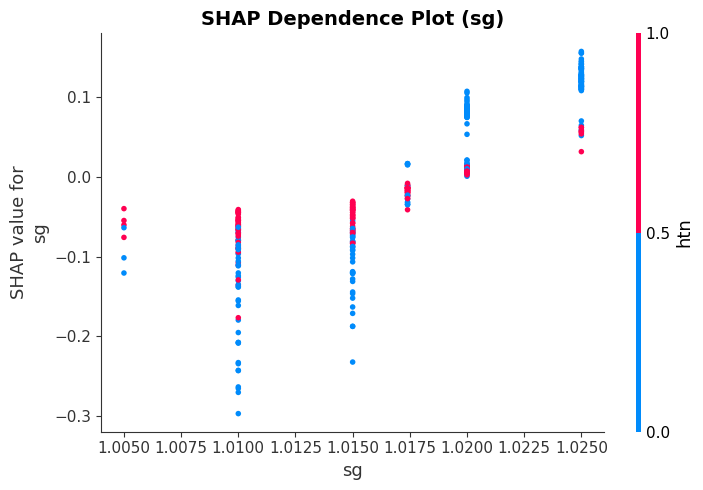


SHAP Dependence Plot Saved Successfully
/content/drive/MyDrive/CKD Research Project/Figures/Explainable_AI/SHAP_Dependence_Plot.png
/content/drive/MyDrive/CKD Research Project/Figures/Explainable_AI/SHAP_Dependence_Plot.pdf


In [25]:
# =============================================================================
# SECTION 14 : SHAP DEPENDENCE PLOT
# =============================================================================

print("=" * 80)
print("GENERATING SHAP DEPENDENCE PLOT")
print("=" * 80)

# ------------------------------------------------------------------
# Select Most Important Feature
# ------------------------------------------------------------------

mean_abs_shap = np.abs(shap_plot.values).mean(axis=0)

top_feature_index = np.argmax(mean_abs_shap)

top_feature_name = X.columns[top_feature_index]

print(f"Top Feature : {top_feature_name}")

# ------------------------------------------------------------------
# Generate Dependence Plot
# ------------------------------------------------------------------

plt.figure(figsize=(10,7))

shap.dependence_plot(
    ind=top_feature_name,
    shap_values=shap_plot.values,
    features=X,
    interaction_index="auto",
    show=False
)

plt.title(
    f"SHAP Dependence Plot ({top_feature_name})",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

dependence_png = os.path.join(
    XAI_FIGURE_DIR,
    "SHAP_Dependence_Plot.png"
)

dependence_pdf = os.path.join(
    XAI_FIGURE_DIR,
    "SHAP_Dependence_Plot.pdf"
)

plt.savefig(
    dependence_png,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    dependence_pdf,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSHAP Dependence Plot Saved Successfully")
print(dependence_png)
print(dependence_pdf)

GENERATING LIME LOCAL EXPLANATION

Sample Index       : 10
Predicted Class    : 0
Prediction Prob.   :
   Not CKD : 1.0000
   CKD     : 0.0000

LIME HTML Explanation Saved Successfully
/content/drive/MyDrive/CKD Research Project/Figures/Explainable_AI/LIME_Explanation.html


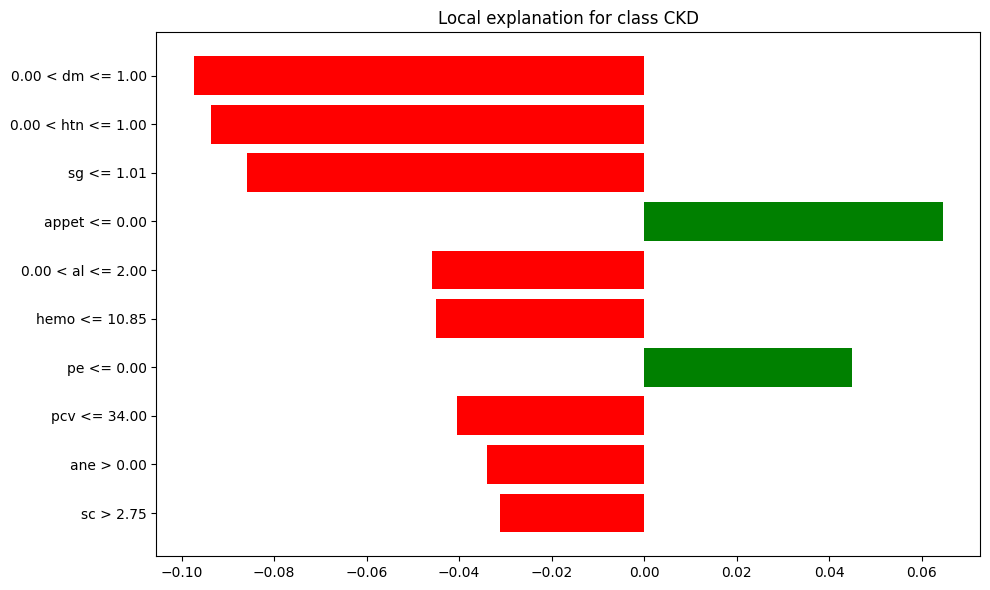


LIME Figures Saved Successfully
/content/drive/MyDrive/CKD Research Project/Figures/Explainable_AI/LIME_Explanation.png
/content/drive/MyDrive/CKD Research Project/Figures/Explainable_AI/LIME_Explanation.pdf

LIME LOCAL EXPLANATION COMPLETED


In [28]:
# =============================================================================
# SECTION 15 : LIME LOCAL EXPLANATION
# =============================================================================

print("=" * 80)
print("GENERATING LIME LOCAL EXPLANATION")
print("=" * 80)

from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt
import os

# ------------------------------------------------------------------
# Create LIME Explainer
# ------------------------------------------------------------------

lime_explainer = LimeTabularExplainer(
    training_data=X.values,
    feature_names=X.columns.tolist(),
    class_names=["Not CKD", "CKD"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# ------------------------------------------------------------------
# Select Sample
# ------------------------------------------------------------------

sample_index = 10      # Change if you want to explain another patient

sample = X.iloc[sample_index].values

# ------------------------------------------------------------------
# Prediction Information
# ------------------------------------------------------------------

prediction = best_model.predict(sample.reshape(1, -1))[0]
probability = best_model.predict_proba(sample.reshape(1, -1))[0]

print(f"\nSample Index       : {sample_index}")
print(f"Predicted Class    : {prediction}")
print(f"Prediction Prob.   :")
print(f"   Not CKD : {probability[0]:.4f}")
print(f"   CKD     : {probability[1]:.4f}")

# ------------------------------------------------------------------
# Generate LIME Explanation
# ------------------------------------------------------------------

lime_exp = lime_explainer.explain_instance(
    data_row=sample,
    predict_fn=best_model.predict_proba,
    num_features=10
)

# ------------------------------------------------------------------
# Save HTML Explanation
# ------------------------------------------------------------------

html_path = os.path.join(
    XAI_FIGURE_DIR,
    "LIME_Explanation.html"
)

lime_exp.save_to_file(html_path)

print("\nLIME HTML Explanation Saved Successfully")
print(html_path)

# ------------------------------------------------------------------
# Visualization
# ------------------------------------------------------------------

fig = lime_exp.as_pyplot_figure()

fig.set_size_inches(10, 6)

lime_png = os.path.join(
    XAI_FIGURE_DIR,
    "LIME_Explanation.png"
)

lime_pdf = os.path.join(
    XAI_FIGURE_DIR,
    "LIME_Explanation.pdf"
)

fig.savefig(
    lime_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    lime_pdf,
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()
plt.close(fig)

print("\nLIME Figures Saved Successfully")
print(lime_png)
print(lime_pdf)

print("\n" + "=" * 80)
print("LIME LOCAL EXPLANATION COMPLETED")
print("=" * 80)

In [31]:
# =============================================================================
# SECTION 16 : EXPORT SHAP FEATURE IMPORTANCE
# =============================================================================

print("=" * 80)
print("EXPORTING SHAP FEATURE IMPORTANCE")
print("=" * 80)

# ------------------------------------------------------------------
# Calculate Mean Absolute SHAP Values
# ------------------------------------------------------------------

feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Mean_SHAP_Value": np.abs(shap_plot.values).mean(axis=0)

})

# ------------------------------------------------------------------
# Sort Features
# ------------------------------------------------------------------

feature_importance = (
    feature_importance
    .sort_values(
        by="Mean_SHAP_Value",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------------
# Round Values
# ------------------------------------------------------------------

feature_importance["Mean_SHAP_Value"] = feature_importance[
    "Mean_SHAP_Value"
].round(6)

# ------------------------------------------------------------------
# Display Top 10 Features
# ------------------------------------------------------------------

print("\nTop 10 Most Important Features\n")

display(feature_importance.head(10))

# ------------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------------

csv_path = os.path.join(
    RESULT_DIR,
    "SHAP_Feature_Importance.csv"
)

feature_importance.to_csv(
    csv_path,
    index=False
)

print("\nSHAP Feature Importance CSV Saved Successfully")
print(csv_path)

print("\n" + "=" * 80)
print("SECTION COMPLETED")
print("=" * 80)

EXPORTING SHAP FEATURE IMPORTANCE

Top 10 Most Important Features



,Feature,Mean_SHAP_Value
0,sg,0.080732
1,dm,0.072942
2,htn,0.070147
3,al,0.051970
4,pcv,0.049214
5,hemo,0.048914
6,appet,0.026042
7,rbcc,0.023324
8,pe,0.021133
9,pc,0.017297



SHAP Feature Importance CSV Saved Successfully
/content/drive/MyDrive/CKD Research Project/Results/SHAP_Feature_Importance.csv

SECTION COMPLETED


In [33]:
# =============================================================================
# SECTION 17 : XAI SUMMARY TABLE
# =============================================================================

print("=" * 80)
print("GENERATING XAI SUMMARY TABLE")
print("=" * 80)

# ------------------------------------------------------------------
# Top 5 Most Important Features
# ------------------------------------------------------------------

top5 = feature_importance.head(5)

summary_df = pd.DataFrame({

    "Rank": range(1, len(top5) + 1),

    "Feature": top5["Feature"].values,

    "Mean_SHAP_Value": top5["Mean_SHAP_Value"].round(5).values

})

# ------------------------------------------------------------------
# Display Summary
# ------------------------------------------------------------------

display(summary_df)

# ------------------------------------------------------------------
# Save Summary
# ------------------------------------------------------------------

summary_csv = os.path.join(
    RESULT_DIR,
    "XAI_Summary.csv"
)

summary_df.to_csv(
    summary_csv,
    index=False
)

print("\nXAI Summary Table Saved Successfully")
print(summary_csv)

print("\n" + "=" * 80)
print("SECTION COMPLETED")
print("=" * 80)

GENERATING XAI SUMMARY TABLE


,Rank,Feature,Mean_SHAP_Value
0,1,sg,0.08073
1,2,dm,0.07294
2,3,htn,0.07015
3,4,al,0.05197
4,5,pcv,0.04921



XAI Summary Table Saved Successfully
/content/drive/MyDrive/CKD Research Project/Results/XAI_Summary.csv

SECTION COMPLETED


In [35]:
# =============================================================================
# SECTION 18 : FINAL XAI SUMMARY & NOTEBOOK COMPLETION
# =============================================================================

print("=" * 80)
print("FINAL XAI SUMMARY")
print("=" * 80)

# ------------------------------------------------------------------
# Create Final Summary
# ------------------------------------------------------------------

xai_summary = {

    "Best Model": best_model_name,

    "Total Samples": X.shape[0],

    "Total Features": X.shape[1],

    "SHAP Analysis": "Completed",

    "SHAP Summary Plot": "Completed",

    "SHAP Feature Importance": "Completed",

    "SHAP Waterfall Plot": "Completed",

    "SHAP Dependence Plot": "Completed",

    "LIME Explanation": "Completed"

}

summary_df = pd.DataFrame(
    list(xai_summary.items()),
    columns=["Component", "Status"]
)

# ------------------------------------------------------------------
# Display Summary
# ------------------------------------------------------------------

display(summary_df)

# ------------------------------------------------------------------
# Save Summary
# ------------------------------------------------------------------

summary_path = os.path.join(
    RESULT_DIR,
    "XAI_Final_Summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

print("\nFinal XAI Summary Saved Successfully")
print(summary_path)

# ------------------------------------------------------------------
# Notebook Completion
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("EXPLAINABLE AI ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 80)

print(f"""
Best Model        : {best_model_name}
Total Samples     : {X.shape[0]}
Total Features    : {X.shape[1]}

Generated Outputs
-----------------
✓ SHAP Summary Plot
✓ SHAP Feature Importance
✓ SHAP Waterfall Plot
✓ SHAP Dependence Plot
✓ LIME Explanation
✓ SHAP_Feature_Importance.csv
✓ XAI_Summary.csv
✓ XAI_Final_Summary.csv

All XAI figures and results have been generated successfully.
""")

FINAL XAI SUMMARY


,Component,Status
0,Best Model,ExtraTreesClassifier
1,Total Samples,399
2,Total Features,24
3,SHAP Analysis,Completed
4,SHAP Summary Plot,Completed
5,SHAP Feature Importance,Completed
6,SHAP Waterfall Plot,Completed
7,SHAP Dependence Plot,Completed
8,LIME Explanation,Completed



Final XAI Summary Saved Successfully
/content/drive/MyDrive/CKD Research Project/Results/XAI_Final_Summary.csv

EXPLAINABLE AI ANALYSIS COMPLETED SUCCESSFULLY

Best Model        : ExtraTreesClassifier
Total Samples     : 399
Total Features    : 24

Generated Outputs
-----------------
✓ SHAP Summary Plot
✓ SHAP Feature Importance
✓ SHAP Waterfall Plot
✓ SHAP Dependence Plot
✓ LIME Explanation
✓ SHAP_Feature_Importance.csv
✓ XAI_Summary.csv
✓ XAI_Final_Summary.csv

All XAI figures and results have been generated successfully.

